In [1]:
# Data handling
import pandas as pd
import numpy as np

# Machine learning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Save trained model
import joblib

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Check dataset shapes
en_train = pd.read_csv("/content/drive/MyDrive/Category-Aware Fake Review Detection/data/processed/processed/en_train.csv")
en_val = pd.read_csv("/content/drive/MyDrive/Category-Aware Fake Review Detection/data/processed/processed/en_val.csv")
en_test = pd.read_csv("/content/drive/MyDrive/Category-Aware Fake Review Detection/data/processed/processed/en_test.csv")
print("Training data:", en_train.shape)
print("Validation data:", en_val.shape)
print("Testing data:", en_test.shape)

# Display first 5 rows
display(en_train.head())

# Check column names
print("\nColumns:", en_train.columns.tolist())

Training data: (29400, 3)
Validation data: (6300, 3)
Testing data: (6301, 3)


,review_text,category,label
0,I enjoyed this film and it has kept me engaged...,movies and tv,1
1,Here's the bonafide truth and what I saw: the ...,clothing shoes and jewelry,1
2,So far the kinds are good. The pieces are stur...,toys and games,1
3,Having used an Apple wireless mini keyboard wi...,electronics,0
4,I had received a pair of these shoes at a disc...,clothing shoes and jewelry,1



Columns: ['review_text', 'category', 'label']


In [4]:
print("Training label distribution:")
print(en_train['label'].value_counts())

print("\nTraining label percentages:")
print(en_train['label'].value_counts(normalize=True) * 100)

print("\nUnique labels:")
print(en_train['label'].unique())

Training label distribution:
label
0    14706
1    14694
Name: count, dtype: int64

Training label percentages:
label
0    50.020408
1    49.979592
Name: proportion, dtype: float64

Unique labels:
[1 0]


In [5]:
# Extract review text
X_train = en_train['review_text']
X_val = en_val['review_text']
X_test = en_test['review_text']

# Extract labels
y_train = en_train['label']
y_val = en_val['label']
y_test = en_test['label']

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 29400
Validation samples: 6300
Testing samples: 6301


fake/genuine label classification:

In [6]:
# Initialize TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    lowercase=True,
    strip_accents='unicode',
    ngram_range=(1, 2),
    max_features=100000,
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

# Fit only on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform validation and testing data
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF conversion completed!")

print("Training matrix:", X_train_tfidf.shape)
print("Validation matrix:", X_val_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

TF-IDF conversion completed!
Training matrix: (29400, 100000)
Validation matrix: (6300, 100000)
Testing matrix: (6301, 100000)


In [7]:
# Initialize Logistic Regression
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model
lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [8]:
# IMPORTANT:
# Change this if your Part 1 label mapping is different.
# Example: 1 = Fake, 0 = Genuine

FAKE_LABEL = 1

# Check that the fake label exists
assert FAKE_LABEL in lr_model.classes_, "Fake label not found!"

# Get fake-review probabilities
fake_class_index = list(lr_model.classes_).index(FAKE_LABEL)

val_probabilities = lr_model.predict_proba(X_val_tfidf)[:, fake_class_index]

# Classification threshold
threshold = 0.5

# Generate predictions
val_predictions = np.where(
    val_probabilities >= threshold,
    FAKE_LABEL,
    next(label for label in lr_model.classes_ if label != FAKE_LABEL)
)

# Calculate evaluation metrics
print("VALIDATION RESULTS")
print("-------------------")

print("Accuracy:", accuracy_score(y_val, val_predictions))

print("Precision:", precision_score(
    y_val, val_predictions, pos_label=FAKE_LABEL
))

print("Recall:", recall_score(
    y_val, val_predictions, pos_label=FAKE_LABEL
))

print("F1 Score:", f1_score(
    y_val, val_predictions, pos_label=FAKE_LABEL
))

print("ROC-AUC:", roc_auc_score(
    (y_val == FAKE_LABEL).astype(int),
    val_probabilities
))

VALIDATION RESULTS
-------------------
Accuracy: 0.9177777777777778
Precision: 0.9322591252877342
Recall: 0.9008579599618685
F1 Score: 0.916289592760181
ROC-AUC: 0.9747368881463334


In [9]:
genuine_label = next(label for label in lr_model.classes_
    if label != FAKE_LABEL)

print(classification_report(
    y_val,
    val_predictions,
    labels=[genuine_label, FAKE_LABEL],
    target_names=['Genuine', 'Fake'],
    zero_division=0
))

              precision    recall  f1-score   support

     Genuine       0.90      0.93      0.92      3153
        Fake       0.93      0.90      0.92      3147

    accuracy                           0.92      6300
   macro avg       0.92      0.92      0.92      6300
weighted avg       0.92      0.92      0.92      6300



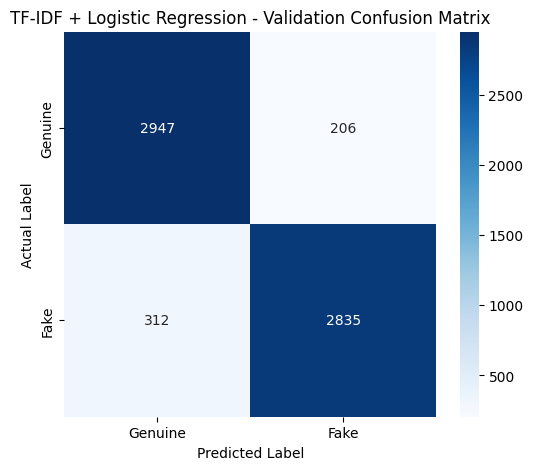

In [10]:
cm = confusion_matrix(
    y_val,
    val_predictions,
    labels=[genuine_label, FAKE_LABEL]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Genuine', 'Fake'],
    yticklabels=['Genuine', 'Fake']
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("TF-IDF + Logistic Regression - Validation Confusion Matrix")

plt.show()

In [11]:
# Predict probabilities on test data
test_probabilities = lr_model.predict_proba(X_test_tfidf)[:, fake_class_index]

# Predict labels
test_predictions = np.where(
    test_probabilities >= threshold,
    FAKE_LABEL,
    genuine_label
)

# Calculate metrics
print("FINAL TEST RESULTS")
print("-------------------")

print("Accuracy:", accuracy_score(y_test, test_predictions))

print("Precision:", precision_score(
    y_test, test_predictions, pos_label=FAKE_LABEL
))

print("Recall:", recall_score(
    y_test, test_predictions, pos_label=FAKE_LABEL
))

print("F1 Score:", f1_score(
    y_test, test_predictions, pos_label=FAKE_LABEL
))

print("ROC-AUC:", roc_auc_score(
    (y_test == FAKE_LABEL).astype(int),
    test_probabilities
))

print("\nClassification Report:")

print(classification_report(
    y_test,
    test_predictions,
    labels=[genuine_label, FAKE_LABEL],
    target_names=['Genuine', 'Fake'],
    zero_division=0
))

FINAL TEST RESULTS
-------------------
Accuracy: 0.9258847801936201
Precision: 0.9449236894492369
Recall: 0.904414099714195
F1 Score: 0.9242252149926984
ROC-AUC: 0.9782396071269099

Classification Report:
              precision    recall  f1-score   support

     Genuine       0.91      0.95      0.93      3152
        Fake       0.94      0.90      0.92      3149

    accuracy                           0.93      6301
   macro avg       0.93      0.93      0.93      6301
weighted avg       0.93      0.93      0.93      6301



In [12]:
# Save TF-IDF vectorizer
joblib.dump(tfidf, 'english_tfidf_vectorizer.pkl')

# Save Logistic Regression model
joblib.dump(lr_model, 'english_logistic_regression.pkl')

print("Models saved successfully!")

Models saved successfully!


In [28]:
fake_review_df = pd.DataFrame({
    'review_text': en_test['review_text'].values,
    'category': en_test['category'].values,
    'original_label': y_test.values,
    'predicted_label': test_predictions
})

# Convert labels into readable names
fake_review_df['original_label'] = fake_review_df['original_label'].map({
    0: 'Genuine',
    1: 'Fake'
})

fake_review_df['predicted_label'] = fake_review_df['predicted_label'].map({
    0: 'Genuine',
    1: 'Fake'
})

display(fake_review_df.head(20))

,review_text,category,original_label,predicted_label
0,I have 2 daughters and found this book while s...,books,Genuine,Genuine
1,This is a wonderful pan. I love the look and f...,home and kitchen,Fake,Fake
2,It's definitely worth the money. I love the lo...,tools and home improvement,Fake,Fake
3,I like the material and the stretchy design. I...,clothing shoes and jewelry,Fake,Fake
4,Using mine for months constant 24/7 and its st...,sports and outdoors,Genuine,Genuine
5,Great little cooker! I use it everyday and it ...,home and kitchen,Fake,Fake
6,We have 4 cats. They all seem to love this lit...,pet supplies,Genuine,Genuine
7,This was a cute story but at times the writing...,kindle store,Genuine,Genuine
8,I totally enjoyed reading this book. The chara...,kindle store,Fake,Fake
9,I was given this book in exchange for an hones...,kindle store,Fake,Fake


Product Category Prediction

In [14]:
print("Number of categories:", en_train['category'].nunique())

print("\nCategory distribution:")
print(en_train['category'].value_counts())

Number of categories: 11

Category distribution:
category
kindle store                  3308
books                         3057
pet supplies                  2975
home and kitchen              2838
electronics                   2792
sports and outdoors           2760
tools and home improvement    2700
clothing shoes and jewelry    2692
toys and games                2651
movies and tv                 2510
hotels                        1117
Name: count, dtype: int64


In [15]:
# Category labels
y_train_cat = en_train['category']
y_val_cat = en_val['category']
y_test_cat = en_test['category']

print("Training categories:", y_train_cat.nunique())
print("Validation categories:", y_val_cat.nunique())
print("Testing categories:", y_test_cat.nunique())

Training categories: 11
Validation categories: 11
Testing categories: 11


In [16]:
# Initialize category classifier
category_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Train using review text features
category_model.fit(
    X_train_tfidf,
    y_train_cat
)

print("Category model training completed!")

Category model training completed!


In [17]:
from sklearn.metrics import accuracy_score, f1_score

# Validation predictions
val_cat_predictions = category_model.predict(X_val_tfidf)

# Evaluation
print("CATEGORY MODEL - VALIDATION RESULTS")
print("-----------------------------------")

print("Accuracy:",
      accuracy_score(y_val_cat, val_cat_predictions))

print("Macro F1:",
      f1_score(
          y_val_cat,
          val_cat_predictions,
          average='macro'
      ))

print("\nClassification Report:")

print(classification_report(
    y_val_cat,
    val_cat_predictions,
    zero_division=0
))

CATEGORY MODEL - VALIDATION RESULTS
-----------------------------------
Accuracy: 0.7976190476190477
Macro F1: 0.8101626868839212

Classification Report:
                            precision    recall  f1-score   support

                     books       0.74      0.76      0.75       655
clothing shoes and jewelry       0.80      0.82      0.81       577
               electronics       0.81      0.81      0.81       598
          home and kitchen       0.70      0.75      0.72       608
                    hotels       1.00      0.99      0.99       240
              kindle store       0.80      0.79      0.79       709
             movies and tv       0.94      0.89      0.92       538
              pet supplies       0.93      0.86      0.89       637
       sports and outdoors       0.65      0.65      0.65       591
tools and home improvement       0.72      0.74      0.73       578
            toys and games       0.83      0.84      0.83       569

                  accuracy  

In [20]:
# Create a DataFrame with actual and predicted categories
category_results = pd.DataFrame({
    'review_text': en_val['review_text'].values,
    'original_category': en_val['category'].values,
    'predicted_category': val_cat_predictions
})

# Check whether prediction is correct
category_results['correct_prediction'] = (category_results['original_category']==category_results['predicted_category'])

# Display results
display(category_results.head(20))

,review_text,original_category,predicted_category,correct_prediction
0,This is a great box set for the whole family. ...,movies and tv,movies and tv,True
1,The OxyLED SL30 is a shining star in the field...,tools and home improvement,tools and home improvement,True
2,This is the book you are looking for. Not a bo...,books,books,True
3,"Adidas fitness gloves, for my 13 year old son....",sports and outdoors,clothing shoes and jewelry,False
4,Arrived very fast with most ants alive. About ...,toys and games,movies and tv,False
5,"Okay, as a reviewer of Sally Bedell Smith's ne...",books,books,True
6,I learned a lot from this book. There is a lot...,kindle store,books,False
7,While this film is about a horrific time it is...,movies and tv,movies and tv,True
8,The advanced power strip surge protection has ...,electronics,electronics,True
9,"Wow, book 2 in the Desert Guard series is even...",kindle store,kindle store,True


In [22]:
category_results.to_csv('/content/drive/MyDrive/Category-Aware Fake Review Detection/english_category_predictions.csv',index=False)

print("Category prediction results saved!")

Category prediction results saved!


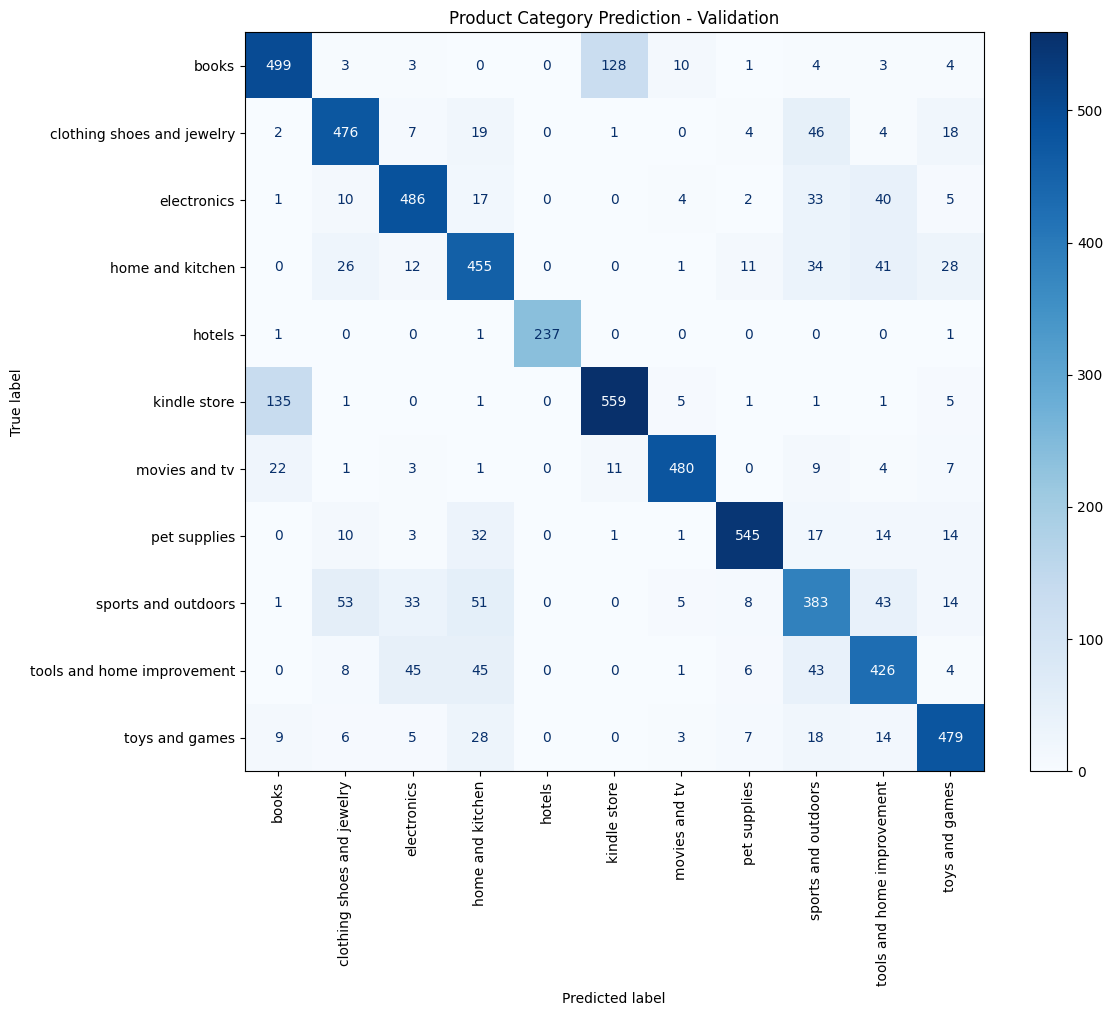

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(
    y_val_cat,
    val_cat_predictions,
    xticks_rotation=90,
    cmap='Blues',
    ax=ax
)

plt.title("Product Category Prediction - Validation")
plt.tight_layout()
plt.show()

Category-Aware Fake Review Detection.

In [29]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.base import clone

# Five-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate out-of-fold category predictions
train_cat_predictions = cross_val_predict(
    category_model,
    X_train_tfidf,
    y_train_cat,
    cv=cv,
    method='predict',
    n_jobs=-1
)

print("Training category predictions completed!")

# Check some predictions
category_check = pd.DataFrame({
    'review_text': en_train['review_text'].values,
    'original_category': y_train_cat.values,
    'predicted_category': train_cat_predictions
})

category_check['correct_prediction'] = (
    category_check['original_category'] ==
    category_check['predicted_category']
)

display(category_check.head(10))

print("\nOOF Category Accuracy:",
      accuracy_score(y_train_cat, train_cat_predictions))

Training category predictions completed!


,review_text,original_category,predicted_category,correct_prediction
0,I enjoyed this film and it has kept me engaged...,movies and tv,movies and tv,True
1,Here's the bonafide truth and what I saw: the ...,clothing shoes and jewelry,clothing shoes and jewelry,True
2,So far the kinds are good. The pieces are stur...,toys and games,toys and games,True
3,Having used an Apple wireless mini keyboard wi...,electronics,electronics,True
4,I had received a pair of these shoes at a disc...,clothing shoes and jewelry,clothing shoes and jewelry,True
5,This is the second streamlight penlight I've h...,tools and home improvement,electronics,False
6,"Won't handle hdmi video for some reason, but i...",electronics,electronics,True
7,In this latest installment of the Star Trek fr...,movies and tv,movies and tv,True
8,"As you can see from the photo, this bra is not...",clothing shoes and jewelry,clothing shoes and jewelry,True
9,I just discovered this show and LOVE it. It is...,movies and tv,movies and tv,True



OOF Category Accuracy: 0.7877210884353741


In [30]:
# Predict categories for validation data
val_cat_predictions = category_model.predict(X_val_tfidf)

# Predict categories for test data
test_cat_predictions = category_model.predict(X_test_tfidf)

print("Validation category predictions completed!")
print("Test category predictions completed!")

Validation category predictions completed!
Test category predictions completed!


In [31]:
category_predictions_df = pd.DataFrame({
    'review_text': en_val['review_text'].values,
    'original_category': en_val['category'].values,
    'predicted_category': val_cat_predictions
})

display(category_predictions_df.head(10))

,review_text,original_category,predicted_category
0,This is a great box set for the whole family. ...,movies and tv,movies and tv
1,The OxyLED SL30 is a shining star in the field...,tools and home improvement,tools and home improvement
2,This is the book you are looking for. Not a bo...,books,books
3,"Adidas fitness gloves, for my 13 year old son....",sports and outdoors,clothing shoes and jewelry
4,Arrived very fast with most ants alive. About ...,toys and games,movies and tv
5,"Okay, as a reviewer of Sally Bedell Smith's ne...",books,books
6,I learned a lot from this book. There is a lot...,kindle store,books
7,While this film is about a horrific time it is...,movies and tv,movies and tv
8,The advanced power strip surge protection has ...,electronics,electronics
9,"Wow, book 2 in the Desert Guard series is even...",kindle store,kindle store


In [32]:
from sklearn.preprocessing import OneHotEncoder
from scipy.sparse import hstack

# Initialize encoder
category_encoder = OneHotEncoder(
    handle_unknown='ignore'
)

# Convert training categories into a DataFrame
train_cat_df = pd.DataFrame({
    'category': train_cat_predictions
})

# Fit encoder on training category predictions
X_train_cat = category_encoder.fit_transform(train_cat_df)

# Transform validation categories
val_cat_df = pd.DataFrame({
    'category': val_cat_predictions
})

X_val_cat = category_encoder.transform(val_cat_df)

# Transform test categories
test_cat_df = pd.DataFrame({
    'category': test_cat_predictions
})

X_test_cat = category_encoder.transform(test_cat_df)

print("Category encoding completed!")

print("Training category features:", X_train_cat.shape)
print("Validation category features:", X_val_cat.shape)
print("Testing category features:", X_test_cat.shape)

Category encoding completed!
Training category features: (29400, 11)
Validation category features: (6300, 11)
Testing category features: (6301, 11)


In [33]:
# Combine text and category features
X_train_combined = hstack([
    X_train_tfidf,
    X_train_cat
]).tocsr()

X_val_combined = hstack([
    X_val_tfidf,
    X_val_cat
]).tocsr()

X_test_combined = hstack([
    X_test_tfidf,
    X_test_cat
]).tocsr()

print("Combined feature matrices created!")

print("Training:", X_train_combined.shape)
print("Validation:", X_val_combined.shape)
print("Testing:", X_test_combined.shape)

Combined feature matrices created!
Training: (29400, 100011)
Validation: (6300, 100011)
Testing: (6301, 100011)


In [34]:
# Initialize category-aware classifier
category_aware_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
category_aware_model.fit(
    X_train_combined,
    y_train
)

print("Category-aware fake review model trained successfully!")

Category-aware fake review model trained successfully!


In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Identify fake and genuine labels
FAKE_LABEL = 1
GENUINE_LABEL = 0

# Get probability column for fake reviews
fake_index_aware = list(category_aware_model.classes_).index(FAKE_LABEL)

# Predict fake probabilities
val_aware_probabilities = category_aware_model.predict_proba(
    X_val_combined
)[:, fake_index_aware]

# Predict labels using threshold 0.5
val_aware_predictions = np.where(
    val_aware_probabilities >= 0.5,
    FAKE_LABEL,
    GENUINE_LABEL
)

# Evaluate
print("CATEGORY-AWARE MODEL - VALIDATION RESULTS")
print("------------------------------------------")

print("Accuracy:",
      accuracy_score(y_val, val_aware_predictions))

print("Precision:",
      precision_score(y_val, val_aware_predictions, pos_label=FAKE_LABEL))

print("Recall:",
      recall_score(y_val, val_aware_predictions, pos_label=FAKE_LABEL))

print("F1 Score:",
      f1_score(y_val, val_aware_predictions, pos_label=FAKE_LABEL))

print("ROC-AUC:",
      roc_auc_score(
          (y_val == FAKE_LABEL).astype(int),
          val_aware_probabilities
      ))

print("\nClassification Report:")

print(classification_report(
    y_val,
    val_aware_predictions,
    labels=[GENUINE_LABEL, FAKE_LABEL],
    target_names=['Genuine', 'Fake'],
    zero_division=0
))

CATEGORY-AWARE MODEL - VALIDATION RESULTS
------------------------------------------
Accuracy: 0.9195238095238095
Precision: 0.93449637919684
Recall: 0.9021290117572291
F1 Score: 0.9180274858528699
ROC-AUC: 0.9763532161430029

Classification Report:
              precision    recall  f1-score   support

     Genuine       0.91      0.94      0.92      3153
        Fake       0.93      0.90      0.92      3147

    accuracy                           0.92      6300
   macro avg       0.92      0.92      0.92      6300
weighted avg       0.92      0.92      0.92      6300



In [36]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Identify fake and genuine labels
FAKE_LABEL = 1
GENUINE_LABEL = 0

# Get probability column for fake reviews
fake_index_aware = list(category_aware_model.classes_).index(FAKE_LABEL)

# Predict fake probabilities
val_aware_probabilities = category_aware_model.predict_proba(
    X_val_combined
)[:, fake_index_aware]

# Predict labels using threshold 0.5
val_aware_predictions = np.where(
    val_aware_probabilities >= 0.5,
    FAKE_LABEL,
    GENUINE_LABEL
)

# Evaluate
print("CATEGORY-AWARE MODEL - VALIDATION RESULTS")
print("------------------------------------------")

print("Accuracy:",
      accuracy_score(y_val, val_aware_predictions))

print("Precision:",
      precision_score(y_val, val_aware_predictions, pos_label=FAKE_LABEL))

print("Recall:",
      recall_score(y_val, val_aware_predictions, pos_label=FAKE_LABEL))

print("F1 Score:",
      f1_score(y_val, val_aware_predictions, pos_label=FAKE_LABEL))

print("ROC-AUC:",
      roc_auc_score(
          (y_val == FAKE_LABEL).astype(int),
          val_aware_probabilities
      ))

print("\nClassification Report:")

print(classification_report(
    y_val,
    val_aware_predictions,
    labels=[GENUINE_LABEL, FAKE_LABEL],
    target_names=['Genuine', 'Fake'],
    zero_division=0
))

CATEGORY-AWARE MODEL - VALIDATION RESULTS
------------------------------------------
Accuracy: 0.9195238095238095
Precision: 0.93449637919684
Recall: 0.9021290117572291
F1 Score: 0.9180274858528699
ROC-AUC: 0.9763532161430029

Classification Report:
              precision    recall  f1-score   support

     Genuine       0.91      0.94      0.92      3153
        Fake       0.93      0.90      0.92      3147

    accuracy                           0.92      6300
   macro avg       0.92      0.92      0.92      6300
weighted avg       0.92      0.92      0.92      6300



In [37]:
# Predict fake probabilities
test_aware_probabilities = category_aware_model.predict_proba(
    X_test_combined
)[:, fake_index_aware]

# Predict fake/genuine labels
test_aware_predictions = np.where(
    test_aware_probabilities >= 0.5,
    FAKE_LABEL,
    GENUINE_LABEL
)

# Evaluate
print("CATEGORY-AWARE MODEL - FINAL TEST RESULTS")
print("-----------------------------------------")

print("Accuracy:",
      accuracy_score(y_test, test_aware_predictions))

print("Precision:",
      precision_score(y_test, test_aware_predictions, pos_label=FAKE_LABEL))

print("Recall:",
      recall_score(y_test, test_aware_predictions, pos_label=FAKE_LABEL))

print("F1 Score:",
      f1_score(y_test, test_aware_predictions, pos_label=FAKE_LABEL))

print("ROC-AUC:",
      roc_auc_score(
          (y_test == FAKE_LABEL).astype(int),
          test_aware_probabilities
      ))

print("\nClassification Report:")

print(classification_report(
    y_test,
    test_aware_predictions,
    labels=[GENUINE_LABEL, FAKE_LABEL],
    target_names=['Genuine', 'Fake'],
    zero_division=0
))

CATEGORY-AWARE MODEL - FINAL TEST RESULTS
-----------------------------------------
Accuracy: 0.9266783050309475
Precision: 0.94501490559788
Recall: 0.9060019053667832
F1 Score: 0.9250972762645915
ROC-AUC: 0.9788712031698084

Classification Report:
              precision    recall  f1-score   support

     Genuine       0.91      0.95      0.93      3152
        Fake       0.95      0.91      0.93      3149

    accuracy                           0.93      6301
   macro avg       0.93      0.93      0.93      6301
weighted avg       0.93      0.93      0.93      6301



In [39]:
# Find the column index corresponding to the Fake label
FAKE_LABEL = 1

fake_index_baseline = list(lr_model.classes_).index(FAKE_LABEL)

print("Model classes:", lr_model.classes_)
print("Fake label index:", fake_index_baseline)

Model classes: [0 1]
Fake label index: 1


In [40]:
# Baseline Model 1 test probabilities
baseline_test_probabilities = lr_model.predict_proba(
    X_test_tfidf
)[:, fake_index_baseline]

baseline_test_predictions = np.where(
    baseline_test_probabilities >= 0.5,
    FAKE_LABEL,
    GENUINE_LABEL
)

# Create final comparison
test_comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC'],

    'Model 1 - Text Only': [
        accuracy_score(y_test, baseline_test_predictions),
        precision_score(y_test, baseline_test_predictions, pos_label=FAKE_LABEL),
        recall_score(y_test, baseline_test_predictions, pos_label=FAKE_LABEL),
        f1_score(y_test, baseline_test_predictions, pos_label=FAKE_LABEL),
        roc_auc_score((y_test == FAKE_LABEL).astype(int),
                      baseline_test_probabilities)
    ],

    'Model 3 - Text + Category': [
        accuracy_score(y_test, test_aware_predictions),
        precision_score(y_test, test_aware_predictions, pos_label=FAKE_LABEL),
        recall_score(y_test, test_aware_predictions, pos_label=FAKE_LABEL),
        f1_score(y_test, test_aware_predictions, pos_label=FAKE_LABEL),
        roc_auc_score((y_test == FAKE_LABEL).astype(int),
                      test_aware_probabilities)
    ]
})

display(test_comparison.round(4))

,Metric,Model 1 - Text Only,Model 3 - Text + Category
0,Accuracy,0.9259,0.9267
1,Precision,0.9449,0.9450
2,Recall,0.9044,0.9060
3,F1 Score,0.9242,0.9251
4,ROC-AUC,0.9782,0.9789


In [41]:
baseline_f1 = f1_score(
    y_test, baseline_test_predictions, pos_label=FAKE_LABEL
)

aware_f1 = f1_score(
    y_test, test_aware_predictions, pos_label=FAKE_LABEL
)

improvement = (aware_f1 - baseline_f1) * 100

print(f"Baseline F1 Score: {baseline_f1:.4f}")
print(f"Category-Aware F1 Score: {aware_f1:.4f}")
print(f"F1 Improvement: {improvement:+.2f} percentage points")

Baseline F1 Score: 0.9242
Category-Aware F1 Score: 0.9251
F1 Improvement: +0.09 percentage points


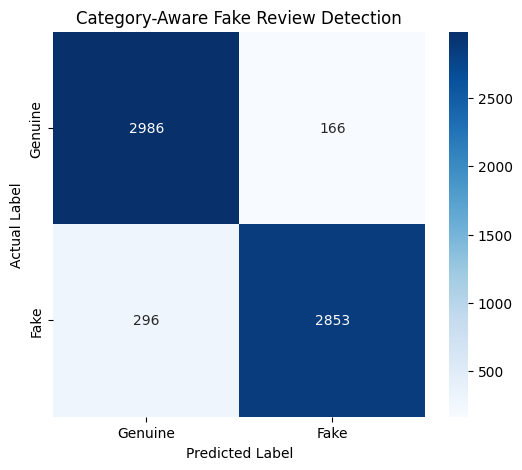

In [42]:
cm = confusion_matrix(
    y_test,
    test_aware_predictions,
    labels=[GENUINE_LABEL, FAKE_LABEL]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Genuine', 'Fake'],
    yticklabels=['Genuine', 'Fake']
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Category-Aware Fake Review Detection")
plt.show()

In [43]:
category_aware_results = pd.DataFrame({
    'review_text': en_test['review_text'].values,
    'original_category': en_test['category'].values,
    'predicted_category': test_cat_predictions,
    'original_label': y_test.values,
    'predicted_label': test_aware_predictions
})

category_aware_results['original_label'] = (
    category_aware_results['original_label']
    .map({0: 'Genuine', 1: 'Fake'})
)

category_aware_results['predicted_label'] = (
    category_aware_results['predicted_label']
    .map({0: 'Genuine', 1: 'Fake'})
)

category_aware_results['correct_prediction'] = (
    category_aware_results['original_label'] ==
    category_aware_results['predicted_label']
)

display(category_aware_results.head(20))

,review_text,original_category,predicted_category,original_label,predicted_label,correct_prediction
0,I have 2 daughters and found this book while s...,books,books,Genuine,Genuine,True
1,This is a wonderful pan. I love the look and f...,home and kitchen,home and kitchen,Fake,Fake,True
2,It's definitely worth the money. I love the lo...,tools and home improvement,tools and home improvement,Fake,Fake,True
3,I like the material and the stretchy design. I...,clothing shoes and jewelry,clothing shoes and jewelry,Fake,Fake,True
4,Using mine for months constant 24/7 and its st...,sports and outdoors,toys and games,Genuine,Genuine,True
5,Great little cooker! I use it everyday and it ...,home and kitchen,home and kitchen,Fake,Fake,True
6,We have 4 cats. They all seem to love this lit...,pet supplies,pet supplies,Genuine,Genuine,True
7,This was a cute story but at times the writing...,kindle store,kindle store,Genuine,Genuine,True
8,I totally enjoyed reading this book. The chara...,kindle store,kindle store,Fake,Fake,True
9,I was given this book in exchange for an hones...,kindle store,kindle store,Fake,Fake,True
